In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import snapatac2 as snap
from scipy.sparse import csr_matrix

In [2]:
he_id = 'CTRL04_2010S1121_75_HE'

In [4]:
atac = sc.read_h5ad(f'../{he_id}_snapATAC_prediction_fullpeaks_allcells_annotated.h5ad')

/home/yl2499/project_pi_rf273/yl2499/ycrc_conda/envs/snapatac2/lib/python3.10/site-packages/anndata/_core/merge.py:1358: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [7]:
with open(f'{he_id}_aggregated_cell_counts_all_cells_50.pickle', 'rb') as handle:
    cell_counts = pickle.load(handle)

In [6]:
fragments_array = atac.X.copy()
fragments_array_final = fragments_array
fragments_array_final_insertion = np.maximum(0, np.ceil(fragments_array_final-0.05)).astype(int)

In [7]:
atac.X = csr_matrix(fragments_array_final_insertion.astype(int).copy())

In [8]:
atac

AnnData object with n_obs × n_vars = 49372 × 32802
    obs: 'x', 'y'

In [9]:
gene_cluster = sc.read_h5ad('DBiT_imputation-CellViT-CTRL04_2010S1121_75_HE_2026_genes_new_all_cells.h5ad')

In [19]:
gene_cluster

AnnData object with n_obs × n_vars = 49372 × 2026
    obs: 'x', 'y', 'section_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'sample_id'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mean', 'std'
    uns: 'leiden_0.6_colors', 'leiden_0.8_colors', 'leiden_1.0_colors', 'spatial', 'wilcoxon_0.6', 'wilcoxon_0.6_selected', 'wilcoxon_0.8_selected'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [20]:
np.sum(gene_cluster.obs_names == atac.obs_names)

49372

In [22]:
atac.obs['gene_leiden_0.6'] = gene_cluster.obs['leiden_0.6']

### motif analysis and peak-gene correlations

In [30]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from tqdm import tqdm

import pybedtools
import pysam

In [31]:
def compute_peak_gene_links(atac, rna, gene_coords, 
                            max_dist=500000, 
                            min_rho=0.2, 
                            max_p=1e-6):
    """
    Compute peak-gene links for paired Multiome data.

    Parameters
    ----------
    atac : AnnData
        scATAC peak x cell matrix.
    rna : AnnData
        scRNA gene x cell matrix.
    gene_coords : dict
        {gene_name: (chrom, tss_position)} dictionary.
    max_dist : int
        maximum distance from peak to gene TSS.
    min_rho : float
        minimum Spearman correlation.
    max_p : float
        maximum p-value for significance.

    Returns
    -------
    DataFrame with columns:
    peak, gene, rho, pval, dist
    """

    peak_coords = [p.replace(":", "-").split("-") for p in atac.var_names]
    peak_positions = [
        (chrom, int(start), int(end)) for chrom, start, end in peak_coords
    ]

    results = []

    atac_matrix = atac.X.toarray()
    rna_matrix = rna.X.copy() #.toarray()

    print("Computing peak–gene correlations...")

    for gi, gene in enumerate(tqdm(rna.var_names)):
        if gene not in gene_coords:
            continue
        chrom_g, pos_g = gene_coords[gene]

        expr = rna_matrix[:, gi]

        for pi, peak in enumerate(atac.var_names):
            chrom_p, start_p, end_p = peak_positions[pi]
            if chrom_p != chrom_g:
                continue

            # TSS distance
            d = min(abs(start_p - pos_g), abs(end_p - pos_g))
            if d > max_dist:
                continue

            acc = atac_matrix[:, pi]

            rho, p = spearmanr(acc, expr)
            if rho >= min_rho and p <= max_p:
                results.append([peak, gene, rho, p, d])

    return pd.DataFrame(results, 
        columns=["peak", "gene", "rho", "pval", "dist"])


In [32]:
genes = gtf[gtf.Feature == "gene"]

genes_start = np.array(genes.Start)
genes_end = np.array(genes.End)
genes_strand = np.array(genes.Strand)
TSS = [x if z == '+' else y for (x, y, z) in zip(genes_start, genes_end, genes_strand)]
genes.TSS = TSS

In [33]:
gene_coords = {}
genes_array = np.array(genes.gene_name)
chr_array = np.array(genes.Chromosome)
tss_array = np.array(genes.TSS)
for i in range(len(genes_array)):
    gene_coords[genes_array[i]] = (chr_array[i], tss_array[i])

In [34]:
links = compute_peak_gene_links(atac=atac, rna=gene_cluster, gene_coords=gene_coords)

Computing peak–gene correlations...


100%|██████████| 2026/2026 [03:03<00:00, 11.01it/s]


In [35]:
len(np.unique(links.gene))

939

In [36]:
import pychromvar as pc

In [37]:
peak_names = [p.replace(":", "-") for p in adata.var_names]
adata.var_names = peak_names

In [38]:
pc.add_peak_seq(adata, genome_file="../ATAC/hg38.fa")

100%|██████████| 32802/32802 [00:07<00:00, 4309.26it/s] 


In [39]:
pc.add_gc_bias(adata)
pc.get_bg_peaks(adata)

100%|██████████| 32802/32802 [00:00<00:00, 51686.11it/s]


In [91]:
from pyjaspar import jaspardb
jdb_obj = jaspardb(release='JASPAR2024')
motifs = jdb_obj.fetch_motifs(
    collection = 'CORE',
    tax_group = ['vertebrates'])

pc.match_motif(adata, motifs=motifs, p_value=5e-05)

100%|██████████| 32802/32802 [03:46<00:00, 144.74it/s]


In [41]:
adata.X = adata.X.astype('float64')

In [42]:
dev = pc.compute_deviations(adata)

2025-11-23 12:08:45 - INFO - computing expectation reads per cell and peak...
2025-11-23 12:08:55 - INFO - computing observed motif deviations...
/nfs/roberts/project/pi_rf273/yl2499/conda/conda_envs/snapatac2/lib/python3.10/site-packages/pychromvar/compute_deviations.py:111: RuntimeWarning: invalid value encountered in divide
  return ((observed - expected) / expected)
2025-11-23 12:09:31 - INFO - computing background deviations...
/nfs/roberts/project/pi_rf273/yl2499/conda/conda_envs/snapatac2/lib/python3.10/site-packages/pychromvar/compute_deviations.py:95: RuntimeWarning: invalid value encountered in divide
  dev = (obs_dev - mean_bg_dev) / std_bg_dev
/nfs/roberts/project/pi_rf273/yl2499/conda/conda_envs/snapatac2/lib/python3.10/site-packages/anndata/_core/anndata.py:402: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


In [43]:
dev

AnnData object with n_obs × n_vars = 49372 × 879

In [44]:
df_pychromvar = pd.DataFrame(dev.X,
                             columns=dev.var_names,
                             index=dev.obs_names)

df_pychromvar.head()

,MA0004.1.Arnt,MA0069.1.PAX6,MA0071.1.RORA,MA0074.1.RXRA::VDR,MA0101.1.REL,MA0107.1.RELA,MA0111.1.Spz1,MA0115.1.NR1H2::RXRA,MA0116.1.Znf423,MA0119.1.NFIC::TLX1,...,MA1730.2.ZNF708,MA0753.3.ZNF740,MA1716.2.ZNF76,MA1731.2.ZNF768,MA1717.2.ZNF784,MA1719.2.ZNF816,MA1720.2.ZNF85,MA1721.2.ZNF93,MA1602.2.ZSCAN29,MA1722.2.ZSCAN31
0,-0.770609,-0.403341,-0.436346,-0.403446,1.047946,1.337476,1.097550,-0.717629,-0.570560,0.946833,...,2.015124,-0.790237,-0.811487,-0.969033,-0.252587,-0.599937,3.070965,0.467243,-0.333261,1.479878
1,-0.490688,-0.971886,-0.327776,-0.950203,0.540829,0.196482,-0.342027,0.056888,-0.267326,-1.019488,...,-0.933984,0.095773,0.971503,-0.529867,-0.946520,1.405759,-0.347352,1.229724,1.103727,-0.684840
2,-0.403469,-0.252560,-0.252614,-0.252642,2.305703,2.720970,-0.369258,-0.369225,-0.333304,-0.369257,...,1.696774,-0.369269,-0.468510,-0.592744,-0.204060,-0.252645,2.290356,2.001877,-0.252599,3.042989
3,-3.264918,0.590538,-2.627956,0.601492,1.763577,1.496152,-2.648222,-2.381502,-5.416705,-5.320342,...,-5.236368,-2.418074,-1.399505,-5.782964,2.828449,-5.559183,-1.340613,6.597576,-1.201159,-2.615999
4,-1.176697,0.184778,-1.797125,-0.294712,1.009082,1.131468,-2.033541,-1.378196,-4.626378,-4.731972,...,-4.021867,-2.254286,-1.673391,-4.505064,0.881912,-4.839838,0.325379,5.992366,-0.293293,-0.984483


In [45]:
df_pychromvar.to_csv('{he_id}_df_pychromvar.csv')

In [48]:
adata.varm['motif_match'].shape

(32802, 879)

In [49]:
adata.varm['motif_hits'].shape

(32802, 2346)

In [5]:
df_pychromvar = pd.read_csv('{he_id}_df_pychromvar.csv')

In [8]:
df_pychromvar = df_pychromvar.drop(['Unnamed: 0'], axis=1)

In [12]:
TFs = df_pychromvar.columns.tolist()

### TF–enhancer–gene GRN assembly

This integrates:

peak→gene links

TF motif hits in those peaks

chromVAR TF activity (optional)

TF expression (optional)

ABC-like distance scoring

Returns a TF–Gene GRN table.

In [120]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

def integrate_layers(
    peak_gene_df,
    motif_hits_df,
    tf_activity_df=None,
    tf_expression_df=None,
    dist_scale=50000,
    min_score=0.01,
    use_motif_scores=False
):
    """
    Build an integrated TF–enhancer–gene GRN using:
    - peak→gene statistical links
    - TF motif hits per peak (DataFrame)
    - optional TF activity (chromVAR / pychromvar)
    - optional TF expression
    - ABC-like distance weighting

    Parameters
    ----------
    peak_gene_df : DataFrame
        Columns: peak, gene, rho, pval, dist
    motif_hits_df : DataFrame (TF × peak)
        TF rows, peak columns.
        Binary (0/1) OR motif scores.
    tf_activity_df : DataFrame (optional)
        Rows = TF, columns = cells (chromVAR Z-scores).
    tf_expression_df : DataFrame (optional)
        Rows = TF, columns = cells.
    dist_scale : int
        Distance decay scale for ABC-like weighting.
    min_score : float
        Minimum GRN score to keep.
    use_motif_scores : bool
        If True, uses numeric motif scores from motif_hits_df.
        If False, any nonzero = 1.

    Returns
    -------
    grn_df : DataFrame
        Columns: TF, Gene, Peak, Score, MotifScore,
                 PeakGeneRho, DistanceWeight, TFsupport
    """

    peaks = motif_hits_df.columns
    TFs = motif_hits_df.index

    grn_records = []

    for _, row in peak_gene_df.iterrows():
        peak = row["peak"]
        gene = row["gene"]
        rho_pg = row["rho"]
        dist = row["dist"]

        if peak not in peaks:
            continue

        # ABC-like distance penalty
        dist_w = 1 / (1 + (dist / dist_scale)**2)

        # all TFs that hit this peak (binary or score-based)
        for tf in TFs:
            motif_val = motif_hits_df.loc[tf, peak]

            # Skip non-hits if binary
            if not use_motif_scores and motif_val <= 0:
                continue

            # If numeric scores, motif_val is the PWM score
            motif_score = float(motif_val)

            # Compute TF support score
            tf_support = 1.0

            # TF expression support (if provided)
            if tf_expression_df is not None and tf in tf_expression_df.index:
                # mean or variance could be used; here mean activity
                tf_exp_val = float(tf_expression_df.loc[tf].mean())
                tf_support *= max(tf_exp_val, 0.01)

            # TF chromVAR activity support
            if tf_activity_df is not None and tf in tf_activity_df.index:
                tf_act_val = float(tf_activity_df.loc[tf].mean())
                tf_support *= max(tf_act_val, 0.01)

            # Final integrated GRN score
            score = rho_pg * motif_score * dist_w * tf_support

            if score >= min_score:
                grn_records.append([
                    tf,
                    gene,
                    peak,
                    score,
                    motif_score,
                    rho_pg,
                    dist_w,
                    tf_support
                ])

    return pd.DataFrame(
        grn_records,
        columns=[
            "TF", "Gene", "Peak", "Score",
            "MotifScore", "PeakGeneRho",
            "DistanceWeight", "TFsupport"
        ]
    ).sort_values("Score", ascending=False)

In [105]:
motif_hits_df = pd.DataFrame(adata.varm['motif_match'].T)

In [114]:
motif_hits_df.columns = adata.var_names
motif_hits_df.index = adata.uns['motif_name']

In [116]:
tf_activity_df = df_pychromvar.T
tf_activity_df.columns = adata.obs_names
tf_activity_df

,0,1,2,3,4,5,6,7,8,9,...,49362,49363,49364,49365,49366,49367,49368,49369,49370,49371
MA0004.1.Arnt,-0.770609,-0.490688,-0.403469,-3.264918,-1.176697,1.018204,2.537538,2.907077,-1.082553,1.838297,...,2.707905,2.141553,2.058465,2.363124,1.978886,2.111192,-0.089913,1.010490,2.379682,2.978009
MA0069.1.PAX6,-0.403341,-0.971886,-0.252560,0.590538,0.184778,-0.817700,-1.103238,-1.137944,1.471757,-1.392204,...,-0.931684,-1.147747,-0.107919,-1.306074,-1.186518,-1.486053,0.268292,-1.029001,-1.416168,-0.688392
MA0071.1.RORA,-0.436346,-0.327776,-0.252614,-2.627956,-1.797125,3.693644,3.933757,2.777522,-2.013374,1.514236,...,3.203177,3.510748,2.989405,3.652511,3.931870,3.974620,1.122894,3.324686,3.969009,3.045129
MA0074.1.RXRA::VDR,-0.403446,-0.950203,-0.252642,0.601492,-0.294712,0.592506,0.216043,0.081126,0.722573,0.597168,...,0.168033,-0.051948,-0.105899,0.210197,0.696953,0.460624,-0.906561,0.660389,0.408028,0.272768
MA0101.1.REL,1.047946,0.540829,2.305703,1.763577,1.009082,0.634668,-0.224517,-1.906402,0.232312,0.115541,...,-1.255583,-1.128067,-0.712566,-1.178984,-0.164730,-0.257443,0.188379,0.155514,-0.022837,-1.499957
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MA1719.2.ZNF816,-0.599937,1.405759,-0.252645,-5.559183,-4.839838,5.093751,5.117484,5.178351,-3.196059,4.300525,...,4.923229,5.098143,4.438212,5.125169,5.024225,5.121951,-0.910472,5.109944,5.374573,5.251518
MA1720.2.ZNF85,3.070965,-0.347352,2.290356,-1.340613,0.325379,1.557404,2.000348,1.748326,-2.187219,0.543784,...,2.339715,2.818731,1.147010,2.544791,2.402820,2.593398,-1.377404,1.678241,1.695587,2.013001
MA1721.2.ZNF93,0.467243,1.229724,2.001877,6.597576,5.992366,-6.284958,-6.435969,-6.507002,6.012228,-5.919533,...,-6.448827,-6.336654,-6.243650,-6.353144,-6.414050,-6.321036,-0.134510,-6.198767,-6.453724,-6.465719
MA1602.2.ZSCAN29,-0.333261,1.103727,-0.252599,-1.201159,-0.293293,1.166398,0.260711,1.055353,-0.792528,1.980241,...,0.219532,0.240135,0.808681,0.052276,0.312684,-0.636730,0.917606,1.291635,0.329357,0.281617


In [129]:
peak = links['peak']
peak_modified = [p.replace(":", "-") for p in peak]
links['peak'] = peak_modified

In [130]:
GRN_df = integrate_layers(peak_gene_df=links, motif_hits_df=motif_hits_df, tf_activity_df=tf_activity_df)

In [131]:
GRN_df

,TF,Gene,Peak,Score,MotifScore,PeakGeneRho,DistanceWeight,TFsupport
1262,MA1620.2.Ptf1A,ACADSB,chr10-123008000-123010000,0.613291,1.0,0.669012,0.999618,0.917063
206008,MA1620.2.Ptf1A,MIER1,chr1-66924000-66926000,0.601055,1.0,0.655623,0.999680,0.917063
192145,MA1620.2.Ptf1A,LYSMD3,chr5-90528000-90530000,0.575921,1.0,0.628050,0.999931,0.917063
346260,MA1620.2.Ptf1A,TPRA1,chr3-127590000-127592000,0.548557,1.0,0.607565,0.984533,0.917063
66776,MA1620.2.Ptf1A,CDS2,chr20-5126000-5128000,0.542910,1.0,0.592192,0.999692,0.917063
...,...,...,...,...,...,...,...,...
200786,MA0498.3.MEIS1,MCU,chr10-72626000-72628000,0.010000,1.0,0.247190,0.378063,0.107008
368037,MA0062.4.GABPA,ULK3,chr15-75028000-75030000,0.010000,1.0,0.423858,0.068311,0.345377
333516,MA2121.1.ZNF213,TEF,chr22-41530000-41532000,0.010000,1.0,0.213973,0.086323,0.541397
353236,MA0598.4.EHF,TSC1,chr9-133116000-133118000,0.010000,1.0,0.462238,0.080377,0.269159


In [ ]:
## PROX1, TTR (CP marker genes), 

In [133]:
GRN_df.to_csv(f'{he_id}_GRN_df.csv')

In [12]:
df_pychromvar= pd.read_csv('{he_id}_df_pychromvar.csv', index_col=0)
df_pychromvar.head()

,MA0004.1.Arnt,MA0069.1.PAX6,MA0071.1.RORA,MA0074.1.RXRA::VDR,MA0101.1.REL,MA0107.1.RELA,MA0111.1.Spz1,MA0115.1.NR1H2::RXRA,MA0116.1.Znf423,MA0119.1.NFIC::TLX1,...,MA1730.2.ZNF708,MA0753.3.ZNF740,MA1716.2.ZNF76,MA1731.2.ZNF768,MA1717.2.ZNF784,MA1719.2.ZNF816,MA1720.2.ZNF85,MA1721.2.ZNF93,MA1602.2.ZSCAN29,MA1722.2.ZSCAN31
0,-0.770609,-0.403341,-0.436346,-0.403446,1.047946,1.337476,1.097550,-0.717629,-0.570560,0.946833,...,2.015124,-0.790237,-0.811487,-0.969033,-0.252587,-0.599937,3.070965,0.467243,-0.333261,1.479878
1,-0.490688,-0.971886,-0.327776,-0.950203,0.540829,0.196482,-0.342027,0.056888,-0.267326,-1.019488,...,-0.933984,0.095773,0.971503,-0.529867,-0.946520,1.405759,-0.347352,1.229724,1.103727,-0.684840
2,-0.403469,-0.252560,-0.252614,-0.252642,2.305703,2.720970,-0.369258,-0.369225,-0.333304,-0.369257,...,1.696775,-0.369269,-0.468510,-0.592744,-0.204060,-0.252645,2.290356,2.001877,-0.252599,3.042990
3,-3.264918,0.590538,-2.627956,0.601492,1.763577,1.496152,-2.648222,-2.381502,-5.416705,-5.320342,...,-5.236368,-2.418074,-1.399505,-5.782964,2.828448,-5.559183,-1.340613,6.597576,-1.201159,-2.616000
4,-1.176697,0.184778,-1.797125,-0.294712,1.009082,1.131468,-2.033541,-1.378196,-4.626378,-4.731972,...,-4.021867,-2.254286,-1.673391,-4.505064,0.881912,-4.839838,0.325379,5.992366,-0.293293,-0.984483


In [24]:
adata_motifs_full = ad.AnnData(X = df_pychromvar)
adata_motifs_full.obs['celltype'] = atac.obs['celltype_final'].copy()
adata_motifs = adata_motifs_full[include_cells, :].copy()
adata_motifs

/home/yl2499/project_pi_rf273/yl2499/ycrc_conda/envs/snapatac2/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 37469 × 879
    obs: 'celltype'

In [25]:
import scanpy as sc

# 1. Ensure your grouping column is available in the motif AnnData object
# Example: Copying cell cluster labels from the original scATAC object
# adata_motifs.obs['cell_clusters'] = original_adata.obs['leiden'] 

# 2. Run the differential test
sc.tl.rank_genes_groups(
    adata_motifs,             # The AnnData object with motif scores
    groupby='celltype',  # The column in .obs that defines your groups
    method='wilcoxon',        # Common statistical test (e.g., 't-test', 'wilcoxon')
    key_added='diff_motifs'   # Key to store results in adata_motifs.uns
)

... storing 'celltype' as categorical
/home/yl2499/project_pi_rf273/yl2499/ycrc_conda/envs/snapatac2/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/yl2499/project_pi_rf273/yl2499/ycrc_conda/envs/snapatac2/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/yl2499/project_pi_rf273/yl2499/ycrc_conda/envs/snapatac2/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/yl2499/project_pi_rf273/yl2499/ycrc_conda/envs/snapatac2/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/yl2499/proje

In [26]:
# Convert results to a clean DataFrame
diff_motif_results = sc.get.rank_genes_groups_df(
    adata_motifs, 
    key='diff_motifs', 
    group=None # e.g., 'Cluster 0'
)

# Filter for the most significant and highest-scoring motifs
top_motifs = diff_motif_results[
    (diff_motif_results['pvals_adj'] < 0.05) & 
    (diff_motif_results['logfoldchanges'] > 2)
]

#print(top_motifs[['names', 'scores', 'logfoldchanges', 'pvals_adj']])

In [27]:
top_motifs

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,Astro,MA0112.4.ESR1,67.457123,3.670815,0.000000e+00,0.000000e+00
1,Astro,MA0646.2.GCM1,62.150135,2.906978,0.000000e+00,0.000000e+00
2,Astro,MA1587.1.ZNF135,61.362789,3.269214,0.000000e+00,0.000000e+00
3,Astro,MA1571.1.TGIF2LX,58.743164,8.790005,0.000000e+00,0.000000e+00
4,Astro,MA0083.3.SRF,58.232147,2.323152,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...
6026,Vascular,MA0679.3.ONECUT1,-29.472464,7.226332,6.490361e-191,2.716680e-190
6056,Vascular,MA1580.1.ZBTB32,-30.046986,2.614641,2.390560e-198,1.469442e-197
6087,Vascular,MA0658.2.LHX6,-30.136492,5.880498,1.612430e-199,1.324604e-198
6107,Vascular,MA0647.2.GRHL1,-30.404903,2.271514,4.731445e-203,5.264481e-202


In [28]:
import scanpy as sc
import pandas as pd

# Define the AnnData object and the results key
adata_motifs = adata_motifs # Your AnnData object containing the motif scores
results_key = 'diff_motifs'
groupby_col = 'celltype' # The column used for grouping

# Function to collect the top N motifs across all groups
def get_top_motifs(adata, results_key, n_top=5):
    all_motifs = []
    
    # Get the names of the groups (e.g., 'Cluster 0', 'Cluster 1', etc.)
    groups = adata.uns[results_key]['names'].dtype.names
    
    for group in groups:
        df = sc.get.rank_genes_groups_df(adata, key=results_key, group=group)
        
        # Filter for significant and positively enriched motifs
        top_n_df = df[
            (df['pvals_adj'] < 0.05) & 
            (df['logfoldchanges'] > 2)
        ].head(n_top)
        
        all_motifs.extend(top_n_df['names'].tolist())
        
    return list(dict.fromkeys(all_motifs)) #list(set(all_motifs)) # Use set to get unique motif names (preserving order)

# Get the list of all differential motifs
top_differential_motifs = get_top_motifs(adata_motifs, results_key, n_top=5)
#top_differential_motifs_full = get_top_motifs(adata_motifs_full, results_key, n_top=5)
print(f"Total unique differential motifs found: {len(top_differential_motifs)}")

Total unique differential motifs found: 32


In [29]:
top_differential_motifs2 = get_top_motifs(adata_motifs, results_key, n_top=7)
top_differential_motifs2

['MA0112.4.ESR1',
 'MA0646.2.GCM1',
 'MA1587.1.ZNF135',
 'MA1571.1.TGIF2LX',
 'MA0083.3.SRF',
 'MA0857.1.Rarb',
 'MA0490.3.JUNB',
 'MA1560.2.SOHLH2',
 'MA1141.2.FOS::JUND',
 'MA1128.2.FOSL1::JUN',
 'MA1120.2.SOX13',
 'MA0143.5.SOX2',
 'MA0514.3.Sox3',
 'MA1421.1.TCF7L1',
 'MA0477.3.FOSL1',
 'MA0655.1.JDP2',
 'MA1556.1.RXRG',
 'MA0859.2.Rarg',
 'MA0090.4.TEAD1',
 'MA2121.1.ZNF213',
 'MA1588.1.ZNF136',
 'MA0105.4.NFKB1',
 'MA0829.3.SREBF1',
 'MA0598.4.EHF',
 'MA1496.2.HOXA4',
 'MA0641.1.ELF4',
 'MA1483.3.ELF2',
 'MA0594.3.HOXA9',
 'MA0135.2.Lhx3',
 'MA1509.1.IRF6',
 'MA0025.3.NFIL3',
 'MA2333.1.ZNF35',
 'MA0078.3.Sox17',
 'MA0692.2.TFEB',
 'MA2094.1.PAX8',
 'MA0142.1.Pou5f1::Sox2',
 'MA0160.3.NR4A2',
 'MA0914.2.ISL2',
 'MA1624.2.Stat5a',
 'MA0669.1.NEUROG2',
 'MA1524.3.Msgn1',
 'MA0080.7.Spi1']

In [30]:
top_differential_motifs_list = ['MA0112.4.ESR1',
                                 'MA0646.2.GCM1',
                                 'MA1587.1.ZNF135',
                                 'MA1571.1.TGIF2LX',
                                 'MA0083.3.SRF',
                                 'MA0857.1.Rarb',
                                 'MA0490.3.JUNB',
                                 'MA1560.2.SOHLH2',
                                 'MA1141.2.FOS::JUND',
                                 'MA1128.2.FOSL1::JUN',
                                 'MA0669.1.NEUROG2',
                                'MA0623.2.NEUROG1', 
                                'MA0670.2.NFIA',
                                'MA1643.2.NFIB', 
                                'MA0161.3.NFIC',
                                 'MA1120.2.SOX13',
                                 'MA0143.5.SOX2',
                                 'MA0514.3.Sox3',
                                 'MA1421.1.TCF7L1',
                                 'MA0477.3.FOSL1',
                                 'MA0655.1.JDP2',
                                 'MA1556.1.RXRG',
                                 'MA0859.2.Rarg',
                                 'MA0090.4.TEAD1',
                                 'MA2121.1.ZNF213',
                                 'MA1588.1.ZNF136',
                                 'MA0105.4.NFKB1',
                                 'MA0829.3.SREBF1',
                                 'MA0598.4.EHF',
                                 'MA1496.2.HOXA4',
                                 'MA0641.1.ELF4',
                                 'MA1483.3.ELF2',
                                 'MA0594.3.HOXA9',
                                 'MA0135.2.Lhx3',
                                 'MA1509.1.IRF6',
                                 'MA0025.3.NFIL3',
                                 'MA2333.1.ZNF35',
                                 'MA0078.3.Sox17',
                                 'MA0692.2.TFEB',
                                 'MA2094.1.PAX8',
                                 'MA0142.1.Pou5f1::Sox2',
                                 'MA0160.3.NR4A2',
                                 'MA0914.2.ISL2',
                               'MA0678.1.OLIG2']#,
#                                 'MA1624.2.Stat5a']#,
#                                'MA1524.3.Msgn1',
#                                 'MA0080.7.Spi1']

In [32]:
adata_motifs

AnnData object with n_obs × n_vars = 37469 × 879
    obs: 'celltype'
    uns: 'diff_motifs'

In [33]:
[motif for motif in adata_motifs.var_names if 'OLIG' in motif]

['MA0678.1.OLIG2', 'MA0826.1.OLIG1', 'MA0827.1.OLIG3']

... storing 'celltype' as categorical


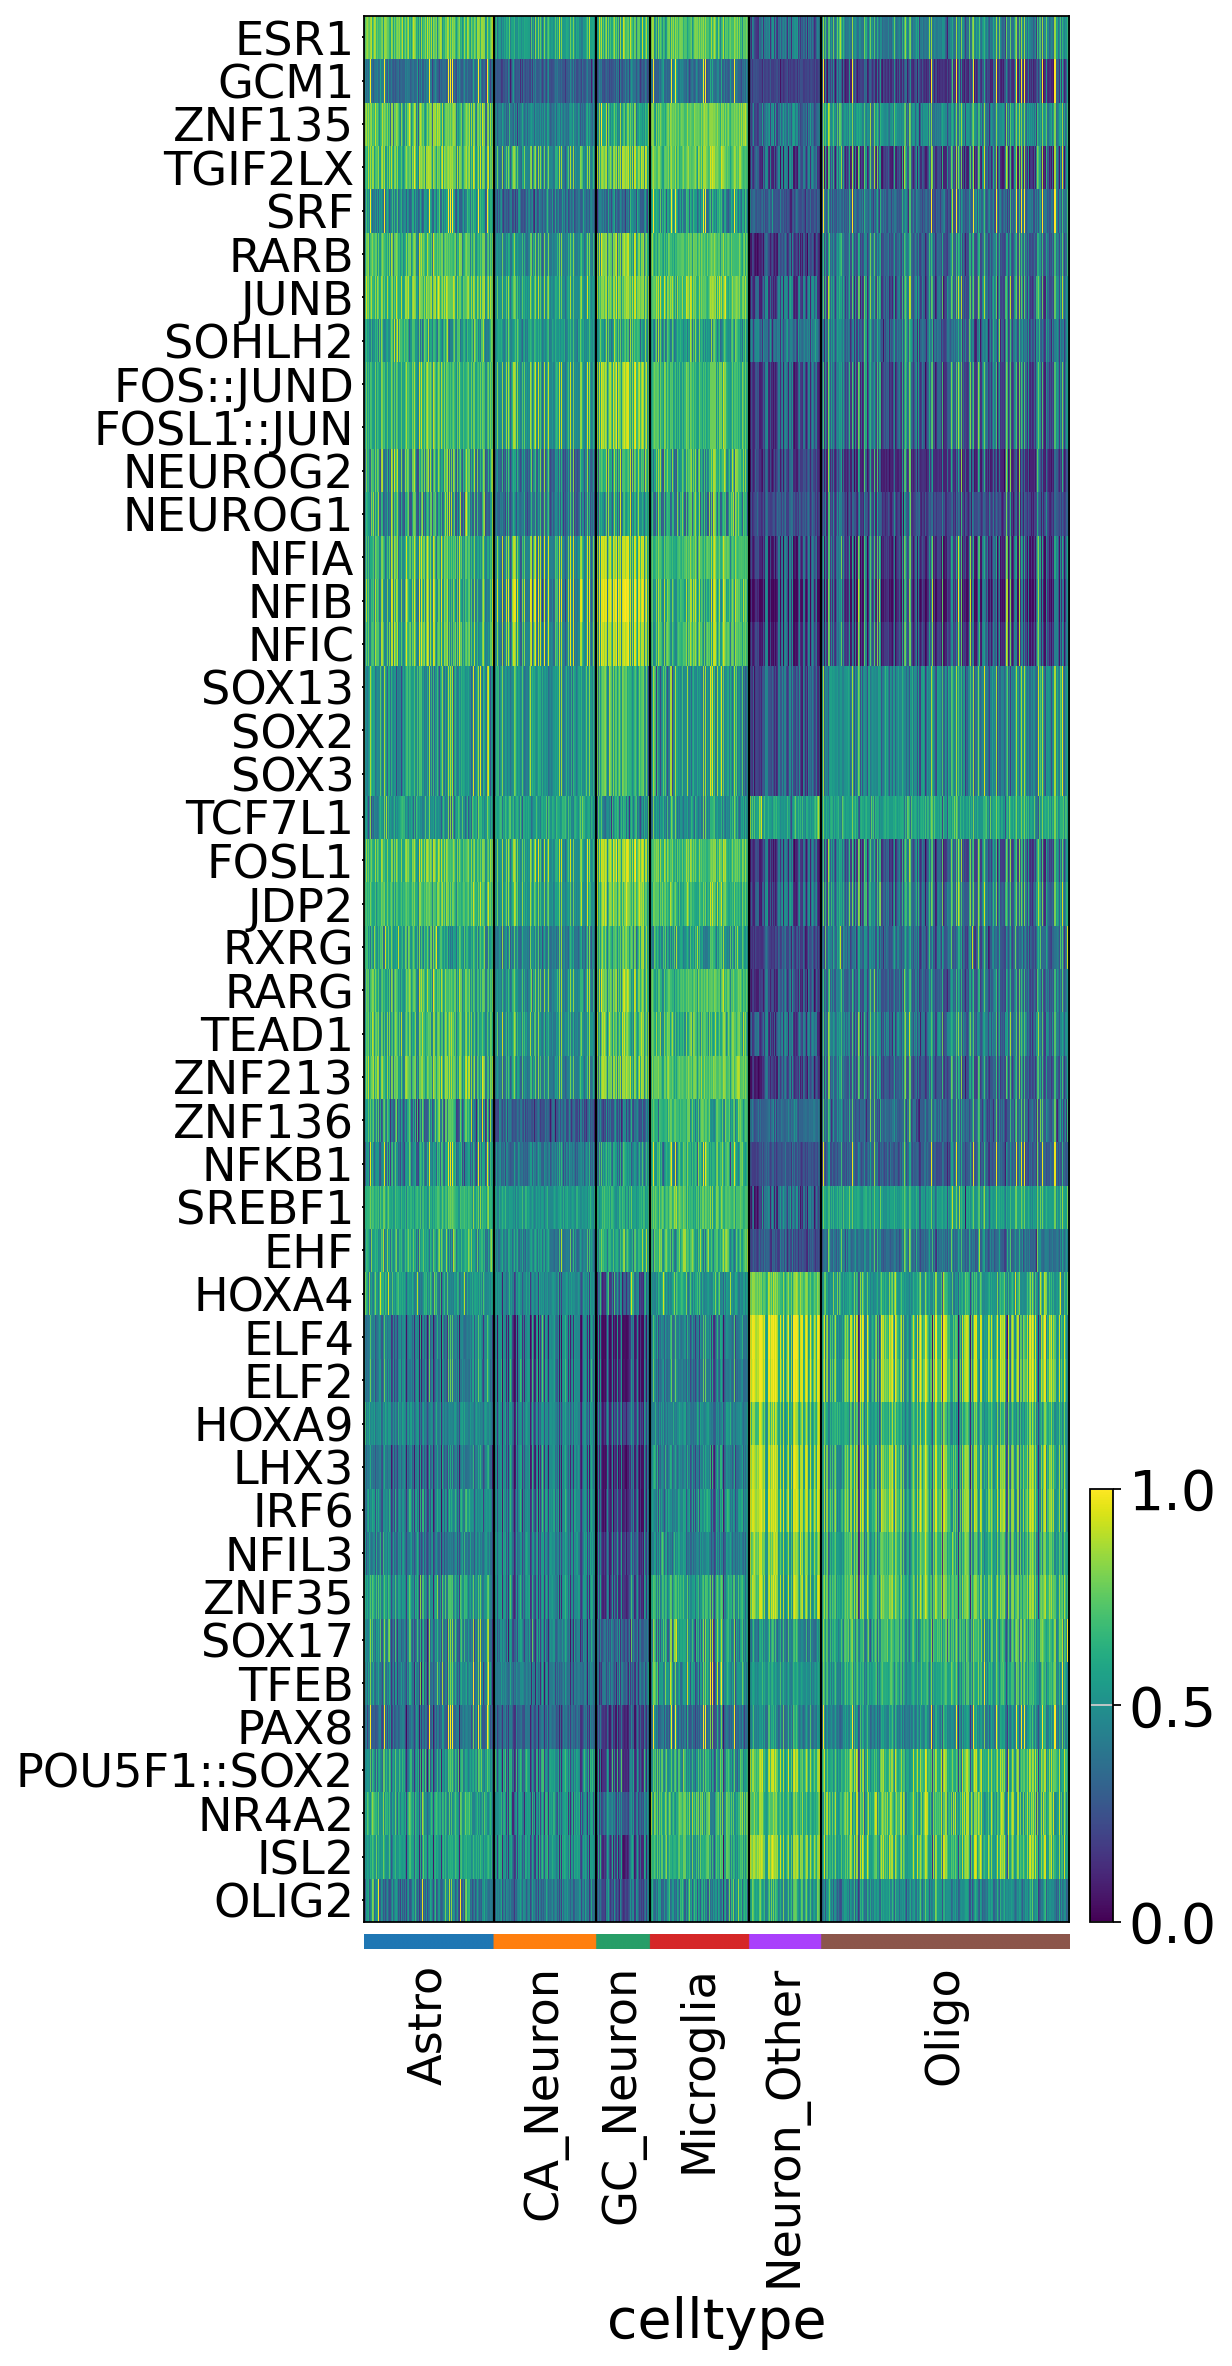

In [42]:
# Create a copy of the AnnData object containing only the top motifs
adata_for_heatmap = adata_motifs[adata_motifs.obs['celltype']!='Vascular', top_differential_motifs_list].copy()
adata_for_heatmap.obs['celltype'] = adata_for_heatmap.obs['celltype'].astype(str)
motif_names = adata_for_heatmap.var_names.tolist()
motif_names2 = [motif.split('.')[-1].upper() for motif in motif_names]
adata_for_heatmap.var_names = motif_names2
adata_for_heatmap.var_names_make_unique()
# Ensure the grouping column is available
#adata_for_heatmap.obs[groupby_col] = adata_motifs.obs[groupby_col]

# Generate the heatmap
#sc.set_figure_params(scanpy=True,figsize=(6,18))
sc.set_figure_params(fontsize=25)
heatmap_obj =sc.pl.heatmap(
    adata_for_heatmap,
    var_names=adata_for_heatmap.var_names, #top_differential_motifs,  # The motifs to display
    groupby=groupby_col,                # The categorical groups (cell clusters)
    standard_scale='var',               # Scale the data per motif (variable) for better comparison
    cmap='viridis',                     # Colormap for the heatmap
    swap_axes=True,
    show_gene_labels=True,
    figsize=(6, 16),
    show=False
)
# 2. Access the Matplotlib Figure object and save it
#heatmap_obj['heatmap_ax'].figure.savefig(f'{he_id}_pychromVAR_motif_heatmap.pdf')
#

In [41]:
GRN_df = pd.read_csv(f'{he_id}_GRN_df.csv', index_col=0)
GRN_df.head()

,TF,Gene,Peak,Score,MotifScore,PeakGeneRho,DistanceWeight,TFsupport
1262,MA1620.2.Ptf1A,ACADSB,chr10-123008000-123010000,0.613291,1.0,0.669012,0.999618,0.917063
206008,MA1620.2.Ptf1A,MIER1,chr1-66924000-66926000,0.601055,1.0,0.655623,0.999680,0.917063
192145,MA1620.2.Ptf1A,LYSMD3,chr5-90528000-90530000,0.575921,1.0,0.628050,0.999931,0.917063
346260,MA1620.2.Ptf1A,TPRA1,chr3-127590000-127592000,0.548557,1.0,0.607565,0.984533,0.917063
66776,MA1620.2.Ptf1A,CDS2,chr20-5126000-5128000,0.542910,1.0,0.592192,0.999692,0.917063


In [138]:
TF_names = [tf.split('.')[-1] for tf in GRN_df['TF']]

In [155]:
GRN_df.loc[GRN_df['TF']=='MA1648.2.TCF12', :]

,TF,Gene,Peak,Score,MotifScore,PeakGeneRho,DistanceWeight,TFsupport
1278,MA1648.2.TCF12,ACADSB,chr10-123008000-123010000,0.529046,1.0,0.669012,0.999618,0.79109
184759,MA1648.2.TCF12,LEPROTL1,chr8-30082000-30084000,0.478443,1.0,0.636268,0.950527,0.79109
248825,MA1648.2.TCF12,PHF7,chr3-52410000-52412000,0.474208,1.0,0.599540,0.999826,0.79109
66787,MA1648.2.TCF12,CDS2,chr20-5126000-5128000,0.468333,1.0,0.592192,0.999692,0.79109
319533,MA1648.2.TCF12,STIM1,chr11-3840000-3842000,0.466715,1.0,0.626990,0.940946,0.79109
...,...,...,...,...,...,...,...,...
198625,MA1648.2.TCF12,MARK1,chr1-220746000-220748000,0.010026,1.0,0.253306,0.050035,0.79109
308308,MA1648.2.TCF12,SMG9,chr19-43532000-43534000,0.010016,1.0,0.259916,0.048710,0.79109
191644,MA1648.2.TCF12,LY6E,chr8-142738000-142740000,0.010015,1.0,0.403950,0.031339,0.79109
380808,MA1648.2.TCF12,ZFP30,chr19-37466000-37468000,0.010013,1.0,0.267456,0.047324,0.79109


In [159]:
type(atac.obs['celltype_final'])

pandas.core.series.Series

In [171]:
rna_data = pd.DataFrame(gene_cluster.layers['counts'])
rna_data.columns = gene_cluster.var_names
rna_data.index = gene_cluster.obs_names
rna_data.head()

,7SK,AATF,ABAT,ABCA6,ABCA7,ABCA9,ABCC1,ABCC10,ABCC8,ABCD4,...,ZNF767P,ZNF773,ZNF786,ZNF814,ZNF836,ZNF875,ZNF92,ZNFX1,ZNRD1ASP,ZRANB1
0,0.126655,0.009177,0.161390,0.026660,0.011990,0.044979,0.046008,0.046918,0.133981,0.041805,...,0.027457,0.021214,0.027819,0.070364,0.010995,0.095235,0.003403,0.057329,0.039782,0.193227
1,0.135789,0.016105,0.183218,0.035544,0.013426,0.056958,0.049425,0.057008,0.125109,0.049551,...,0.028053,0.024644,0.031092,0.080058,0.017018,0.099874,0.004900,0.068760,0.045786,0.205988
2,0.053352,0.005713,0.073946,0.016426,0.010752,0.025153,0.019254,0.021537,0.037382,0.018451,...,0.007953,0.010466,0.009179,0.031942,0.003975,0.045517,0.001122,0.036907,0.021535,0.068470
3,0.116169,0.019771,0.145156,0.034191,0.013824,0.052029,0.051331,0.042833,0.086000,0.045292,...,0.016962,0.025293,0.018089,0.069095,0.018728,0.066195,0.007651,0.076389,0.032458,0.141772
4,0.062789,0.016917,0.060728,0.019139,0.010416,0.029241,0.020665,0.021657,0.016921,0.029522,...,0.003368,0.014417,0.006237,0.032448,0.010074,0.046002,0.003192,0.063261,0.025139,0.068986


In [146]:
from grn_analyzer import GRNAnalyzer

In [172]:
grn_obj = GRNAnalyzer(grn_df=GRN_df, rna_df=rna_data, clusters=atac.obs['celltype_final'])

In [173]:
tf_clusters = grn_obj.cluster_driver_tfs()

/nfs/roberts/project/pi_rf273/yl2499/STAlign/grn_analyzer.py:93: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[tf] = self.regulon_auc(tf, genes)
/nfs/roberts/project/pi_rf273/yl2499/STAlign/grn_analyzer.py:93: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[tf] = self.regulon_auc(tf, genes)
/nfs/roberts/project/pi_rf273/yl2499/STAlign/grn_analyzer.py:93: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all col

In [174]:
tf_clusters

{'Microglia':                    TF  DriverScore   AUCdiff  Ntargets
 254  MA1602.2.ZSCAN29    -0.013054 -0.018832         1
 128     MA0780.1.PAX3    -0.045114 -0.025179         5
 271    MA1640.2.MEIS2    -0.049517 -0.020650        10
 58      MA0486.2.HSF1    -0.052958 -0.027215         6
 166    MA1104.3.GATA6    -0.057756 -0.021328        14
 307    MA1970.2.TRPS1    -0.057756 -0.021328        14
 108     MA0712.3.OTX2    -0.058994 -0.022354        13
 177    MA1121.2.TEAD2    -0.062780 -0.027265         9
 149      MA0825.2.MNT    -0.066032 -0.024384        14
 8        MA0058.4.MAX    -0.066032 -0.024384        14,
 'Astro':                    TF  DriverScore   AUCdiff  Ntargets
 254  MA1602.2.ZSCAN29    -0.014258 -0.020570         1
 128     MA0780.1.PAX3    -0.049075 -0.027389         5
 271    MA1640.2.MEIS2    -0.053291 -0.022224        10
 58      MA0486.2.HSF1    -0.057126 -0.029357         6
 307    MA1970.2.TRPS1    -0.061461 -0.022696        14
 166    MA1104.3.GATA6   

In [165]:
import networkx as nx

def build_grn_graph(grn_df):
    """
    Build a directed TF → Gene regulatory graph from GRN dataframe.
    """
    G = nx.DiGraph()

    for _, row in grn_df.iterrows():
        tf = row["TF"]
        gene = row["Gene"]
        score = float(row["Score"])
        peak = row["Peak"]

        # add directed edge TF → Gene
        G.add_edge(tf, gene, weight=score, peak=peak)

    return G

G = build_grn_graph(GRN_df)
print(G.number_of_nodes(), G.number_of_edges())

1242 156303


In [57]:
grn_filtered = GRN_df[GRN_df["Score"] > 0.1]
grn_filtered

,TF,Gene,Peak,Score,MotifScore,PeakGeneRho,DistanceWeight,TFsupport
1262,MA1620.2.Ptf1A,ACADSB,chr10-123008000-123010000,0.613291,1.0,0.669012,0.999618,0.917063
206008,MA1620.2.Ptf1A,MIER1,chr1-66924000-66926000,0.601055,1.0,0.655623,0.999680,0.917063
192145,MA1620.2.Ptf1A,LYSMD3,chr5-90528000-90530000,0.575921,1.0,0.628050,0.999931,0.917063
346260,MA1620.2.Ptf1A,TPRA1,chr3-127590000-127592000,0.548557,1.0,0.607565,0.984533,0.917063
66776,MA1620.2.Ptf1A,CDS2,chr20-5126000-5128000,0.542910,1.0,0.592192,0.999692,0.917063
...,...,...,...,...,...,...,...,...
333922,MA0801.1.MGA,TIMM17A,chr1-201954000-201956000,0.100005,1.0,0.277525,0.999901,0.360383
256009,MA1947.2.ETV5::FOXO1,POLDIP3,chr22-42582000-42584000,0.100005,1.0,0.348224,0.722826,0.397311
211022,MA1100.3.ASCL1,MRAS,chr3-138328000-138330000,0.100004,1.0,0.298740,0.889231,0.376450
29842,MA0155.1.INSM1,BAG5,chr14-103546000-103548000,0.100003,1.0,0.445951,0.920869,0.243516


In [85]:
selected_TF = [True if ('NFIA' in TF)+('NFIB' in TF)+('NFIC' in TF) else False for TF in np.array(grn_filtered.TF) ]
NFI_GRN = grn_filtered.loc[selected_TF, :].copy()
NFI_GRN

,TF,Gene,Peak,Score,MotifScore,PeakGeneRho,DistanceWeight,TFsupport
319631,MA0161.3.NFIC,STIM1,chr11-3854000-3856000,0.520253,1.0,0.643911,0.999889,0.808047
187791,MA0161.3.NFIC,LPCAT1,chr5-1522000-1524000,0.518235,1.0,0.641343,0.999999,0.808047
66761,MA0161.3.NFIC,CDS2,chr20-5126000-5128000,0.478371,1.0,0.592192,0.999692,0.808047
205346,MA0161.3.NFIC,METTL25,chr12-82358000-82360000,0.475752,1.0,0.588834,0.999889,0.808047
400672,MA0161.3.NFIC,ZNF836,chr19-52188000-52190000,0.471153,1.0,0.645478,0.903326,0.808047
...,...,...,...,...,...,...,...,...
286390,MA1527.2.NFIC,RMDN3,chr15-40766000-40768000,0.100177,1.0,0.208303,0.960429,0.500735
167811,MA1643.2.NFIB,HPS5,chr11-18396000-18398000,0.100176,1.0,0.463523,0.314595,0.686974
336631,MA1527.2.NFIC,TMEM177,chr2-119678000-119680000,0.100168,1.0,0.200099,0.999722,0.500735
140377,MA1643.2.NFIB,FDPS,chr1-155254000-155256000,0.100035,1.0,0.307675,0.473284,0.686974


In [86]:
np.unique(NFI_GRN.Gene)

array(['ABI1', 'ACADSB', 'ACTN1', 'ACTR1A', 'ADAM11', 'ADRA1A', 'AGPAT5',
       'AIG1', 'AKT2', 'AKTIP', 'AMDHD2', 'ANAPC1', 'ANKH', 'ANKMY2',
       'ANKRD20A19P', 'ANKRD33B', 'ANKRD34A', 'ANXA11', 'ANXA6', 'AP1AR',
       'AP5Z1', 'ARF3', 'ARFGAP2', 'ARHGAP32', 'ARHGEF4', 'ARIH1',
       'ARL16', 'ARL8A', 'ARMC1', 'ARMC10', 'ARNTL', 'ARRDC1', 'ASCC1',
       'ATAD1', 'ATAD3B', 'ATP2B1-AS1', 'ATP6AP2', 'ATP6V1H', 'ATXN2L',
       'ATXN7L3', 'AUH', 'B3GALNT1', 'BAG5', 'BAIAP3', 'BCAS4', 'BCR',
       'BDH1', 'BIN3', 'BOLA3-AS1', 'BRINP2', 'BRSK1', 'BTN3A2', 'BTRC',
       'C16orf72', 'C1orf115', 'C1orf50', 'C3orf14', 'C3orf62', 'CA11',
       'CACNB4', 'CACUL1', 'CALM2P3', 'CAMK2A', 'CAMKK1', 'CAND1',
       'CAND2', 'CAPZA1', 'CARM1', 'CARMIL1', 'CARS1', 'CASKIN1',
       'CASTOR3', 'CAT', 'CC2D1A', 'CCDC112', 'CCDC181', 'CCDC43',
       'CCDC59', 'CCDC74A', 'CCT5', 'CCT6P1', 'CDC42SE1', 'CDIPT',
       'CDK10', 'CDR2', 'CDS2', 'CELSR3', 'CENPCP1', 'CENPT', 'CEP68',
       'CEP76', '

In [87]:
selected_nfi_genes = ['CAMK2A', 'NLGN1', 'SYN1', 'SLC17A7', 'NOS1', 'KCNB2', 'KCNC3', 'SLIT1', 'SLIT3', 'CELSR3', 'NEUROD1', 'OLIG2', 'FOXG1', 'GRIN2A', 'DOCK3', 'LASP1', 'MARK1', 'ANXA11', 'XPR1', 'ARHGAP32', 'SST', 'DUSP22', 'DUSP7', 'DUSP8', 'PROX1', 'NOVA1', 'LRP8', 'DAB2IP', 'SPAST', 'GIT2', 'TMEM119', 'LMTK2', 'CAMK4', 'CAMKK1', 'NCK1', 'CELSR3', 'E2F3', 'FGF9', 'COL4A1', 'EGR3', 'KMT2D', 'LATS1', 'LATS2', 'RHEB', 'TSC1', 'SRF', 'TUBB3', 'TUBA4A', 'TUBB4A', 'WDR5', 'ULK3']
selected_nfi_rows = [True if gene in selected_nfi_genes else False for gene in NFI_GRN.Gene]
NFI_GRN_sub = NFI_GRN.loc[selected_nfi_rows, :].copy()

In [88]:
TF_name = [TF.split('.')[-1] for TF in NFI_GRN_sub.TF]
NFI_GRN_sub['TF_name'] = TF_name
NFI_GRN_sub['uid'] = NFI_GRN_sub['TF_name'].astype(str)+'_'+NFI_GRN_sub['Gene'].astype(str)
NFI_GRN_sub = NFI_GRN_sub.sort_values(by=['uid', 'Score'], ascending=[True, False])
NFI_GRN_sub_uniq = NFI_GRN_sub.drop_duplicates(subset=['uid'], keep='first')

In [89]:
NFI_GRN_sub_uniq

,TF,Gene,Peak,Score,MotifScore,PeakGeneRho,DistanceWeight,TFsupport,TF_name,uid
12797,MA0670.2.NFIA,ANXA11,chr10-80202000-80204000,0.160125,1.0,0.237754,0.999013,0.674155,NFIA,NFIA_ANXA11
17986,MA0670.2.NFIA,ARHGAP32,chr11-129278000-129280000,0.202540,1.0,0.300491,0.999817,0.674155,NFIA,NFIA_ARHGAP32
47587,MA0670.2.NFIA,CAMKK1,chr17-3896000-3898000,0.255723,1.0,0.379510,0.999508,0.674155,NFIA,NFIA_CAMKK1
67989,MA0670.2.NFIA,CELSR3,chr3-48656000-48658000,0.251741,1.0,0.376983,0.990541,0.674155,NFIA,NFIA_CELSR3
99028,MA0670.2.NFIA,DAB2IP,chr9-121546000-121548000,0.145078,1.0,0.246457,0.873170,0.674155,NFIA,NFIA_DAB2IP
...,...,...,...,...,...,...,...,...,...,...
352864,MA0161.3.NFIC,TSC1,chr9-132878000-132880000,0.101931,1.0,0.351799,0.358570,0.808047,NFIC,NFIC_TSC1
360367,MA0161.3.NFIC,TUBA4A,chr2-219286000-219288000,0.395497,1.0,0.502287,0.974439,0.808047,NFIC,NFIC_TUBA4A
361157,MA0161.3.NFIC,TUBB3,chr16-89874000-89876000,0.100629,1.0,0.227166,0.548204,0.808047,NFIC,NFIC_TUBB3
361872,MA0161.3.NFIC,TUBB4A,chr19-6516000-6518000,0.252879,1.0,0.334604,0.935287,0.808047,NFIC,NFIC_TUBB4A


In [90]:
NFI_GRN_sub_uniq.to_csv(f'{he_id}_selected_NFI_GRN.csv')